In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
#梯度 = 导数
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,GradientBoostingClassifier,GradientBoostingRegressor
from sklearn import datasets

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier

from sklearn import tree

![](梯度提升二分类_log.png)

In [5]:
xi = np.arange(1,11)
yi = np.array([0,0,0,1,1]*2)

In [8]:
gbdt = GradientBoostingClassifier(n_estimators=3,max_depth=1)

gbdt.fit(xi.reshape(-1,1),yi)


GradientBoostingClassifier(max_depth=1, n_estimators=3)

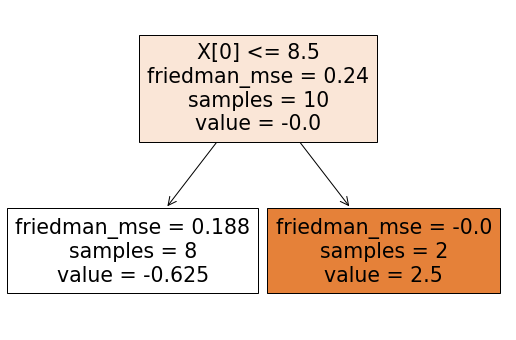

In [13]:
gbdt.estimators_
plt.figure(figsize=(9,6))
_ = tree.plot_tree(gbdt[0][0],filled=True,)

#计算F0的值$$F_0$$

In [16]:
F0 = np.log(4/6)
F0


-0.40546510810816444

#计算
$$\widetilde{y}_i$$

In [21]:
#第一次求yi
yi_1 = yi - 1/(1 + np.exp(-F0))
yi_1

array([-0.4, -0.4, -0.4,  0.6,  0.6, -0.4, -0.4, -0.4,  0.6,  0.6])

In [26]:
# 计算每个列分点的MSE
mse1 = []
for i in range(1,11):
    if i==10:
        mse1.append(np.var(yi_1))
    else:
        mse1.append((np.var(yi_1[:i]) * i + np.var(yi_1[i:]) *(10-i))/10)

mse1 = np.asarray(mse1)
mse1

array([0.22222222, 0.2       , 0.17142857, 0.225     , 0.24      ,
       0.23333333, 0.20952381, 0.15      , 0.2       , 0.24      ])

In [28]:
yi_1[:8].sum() / (((yi[:8] - yi_1[:8]) * (1- yi[:8] + yi_1[:8])).sum())

-0.6250000000000001

In [29]:
yi_1[8:].sum() / (((yi[8:] - yi_1[8:]) * (1- yi[8:] + yi_1[8:])).sum())

2.5

In [30]:
gbdt[0,0].predict(xi.reshape(-1,1))

array([-0.625, -0.625, -0.625, -0.625, -0.625, -0.625, -0.625, -0.625,
        2.5  ,  2.5  ])

In [34]:
y_1 = [-0.625]*8 + [2.5]*2
y_1 = np.asarray(y_1)
y_1

array([-0.625, -0.625, -0.625, -0.625, -0.625, -0.625, -0.625, -0.625,
        2.5  ,  2.5  ])